# One axis, 17 honest indicators

Third piece in this thread. `dc_ej_predictors.ipynb` found that `fiber_score` (distance to nearest internet carrier hotel) was the #1 predictor of WA's real EJ index -- and that this wasn't really a broadband story, it was `fiber_score` acting as a stand-in for one underlying urban/industrial-density axis, alongside `pop_exposure_score`, `water_score`, and others. This piece makes that claim precise instead of qualitative: PCA on WA's physical/infrastructure indicators, to actually quantify how dominant that one axis is, see everything that loads onto it, and visualize it directly rather than gesturing at a correlation table.

**Leakage correction (2026-08-28):** the first version of this notebook ran PCA on all 21 physical indicators, including `contamination_score`, `superfund_score`, `rcra_score`, `air_quality_score` -- the same 4 columns that are literally the raw ingredients of `env_burden`, which is half of `ej_index`'s own formula. Those 4 columns had among the largest loadings on that PC1 (tied with `fiber_score`), so a meaningful share of the reported explanatory power was mechanical, not a real urban/rural finding -- a version of exactly the leakage check `dc_ej_predictors.ipynb`'s random forest already did, just missed here at the time because "PCA doesn't predict `ej_index`, it just describes the indicators" stopped being true the moment PC1 was then used *to* predict `ej_index`. Caught by asking "wait, did we check for leakage here" after this notebook, and two others built on top of it, had already shipped with the inflated number. Rebuilt throughout excluding the 4 hazard columns entirely from the PCA input, not just flagged.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd

zctas = gpd.read_file("../../merascope/data/WA/zcta/grid_scores.geojson")
acs = pd.read_csv("data/acs_demog_moe_tract_wa.csv", dtype={"GEOID": str})
tracts = gpd.read_file("../../merascope/data/WA/raw/tracts.geojson")[["GEOID", "geometry"]].merge(acs, on="GEOID")

zctas_m = zctas.to_crs(3857)
tracts_m = tracts.set_geometry("geometry").to_crs(3857)
tracts_m["tract_area"] = tracts_m.geometry.area
overlay = gpd.overlay(zctas_m[["zcta", "geometry"]], tracts_m, how="intersection", keep_geom_type=False)
overlay["piece_area"] = overlay.geometry.area
overlay = overlay.merge(tracts_m[["GEOID", "tract_area"]], on="GEOID", suffixes=("", "_full"))
overlay["pop_weight"] = overlay["tract_pop"] * (overlay["piece_area"] / overlay["tract_area"])


def weighted_demog(g):
    w = g["pop_weight"]
    return pd.Series({"demog_index": np.nan}) if w.sum() <= 0 else pd.Series({"demog_index": np.average(g["demog_index"], weights=w)})


zcta_di = overlay.groupby("zcta").apply(weighted_demog, include_groups=False).reset_index()
zctas = zctas.merge(zcta_di, on="zcta", how="left")

ENV_HAZARD_COLS = ["contamination_score", "superfund_score", "rcra_score", "air_quality_score"]
zctas["env_burden"] = 1 - zctas[ENV_HAZARD_COLS].mean(axis=1)
zctas["ej_index"] = zctas["demog_index"] * zctas["env_burden"]
zctas = zctas.dropna(subset=["ej_index"]).copy()
print(f"{len(zctas)} WA ZCTAs with a real EJ index (same construction as the companion pieces)")

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


591 WA ZCTAs with a real EJ index (same construction as the companion pieces)


## PCA on the 17 honest indicators

Leakage guard, by construction: `env_burden` (half of `ej_index`) is literally built from `ENV_HAZARD_COLS`. Excluded from the PCA input entirely, not just flagged afterward -- the mistake in the first version of this notebook was trusting a correlation-threshold-style argument ("PCA doesn't predict the target") instead of tracing where the target's own raw ingredients could re-enter through a back door. Standardized first (z-score each indicator) so PCA isn't dominated by whichever column happens to have the widest natural range.

In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

PCA_COLS = [c for c in zctas.columns
            if c.endswith("_score") and not c.endswith("_score_nat")
            and c not in ("ej_score", "grid_capacity_score")
            and c not in ENV_HAZARD_COLS]
assert not (set(PCA_COLS) & set(ENV_HAZARD_COLS)), "a hazard column leaked back into the PCA input"
print(f"{len(PCA_COLS)} indicators:", PCA_COLS)

X = zctas[PCA_COLS].to_numpy()
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=len(PCA_COLS), random_state=0)
scores = pca.fit_transform(Xs)
evr = pca.explained_variance_ratio_

chance = 1 / len(PCA_COLS)
print(f"\nPC1 explains {evr[0]*100:.1f}% of variance -- {evr[0]/chance:.1f}x more than the {chance*100:.1f}% "
      f"a random axis would get across {len(PCA_COLS)} indicators")
print(f"PC2: {evr[1]*100:.1f}%, PC3: {evr[2]*100:.1f}%")
assert evr[0] > 3 * chance, "PC1 isn't actually dominant -- don't claim a single urban/rural axis"

loadings1 = pd.Series(pca.components_[0], index=PCA_COLS).sort_values(key=abs, ascending=False)
print("\nPC1 loadings, ranked by |loading|:")
print(loadings1.round(3))

17 indicators: ['tx_score', 'water_score', 'pop_exposure_score', 'seismic_score', 'flood_score', 'waterway_score', 'geothermal_score', 'flatness_score', 'protected_score', 'slope_score', 'aquifer_score', 'soil_score', 'soil_profile_score', 'ksat_score', 'substation_score', 'fiber_score', 'water_stress_score']

PC1 explains 24.6% of variance -- 4.2x more than the 5.9% a random axis would get across 17 indicators
PC2: 15.0%, PC3: 11.5%

PC1 loadings, ranked by |loading|:
fiber_score           0.369
pop_exposure_score   -0.353
slope_score           0.352
flatness_score        0.352
tx_score              0.304
substation_score      0.284
seismic_score        -0.255
geothermal_score     -0.246
ksat_score           -0.236
water_score           0.232
soil_score           -0.189
aquifer_score        -0.164
water_stress_score   -0.104
waterway_score       -0.082
soil_profile_score   -0.059
flood_score          -0.011
protected_score      -0.001
dtype: float64


## Is PC1 actually the urban/rural axis, or just the direction of most variance?

PCA finds the direction of maximum variance -- that doesn't automatically mean it's "urban/rural." Checked against the two known density proxies from the companion piece (`fiber_score`, `pop_exposure_score`) before calling it that, rather than assuming the label fits.

In [3]:
pc1 = scores[:, 0]
if np.corrcoef(pc1, zctas["fiber_score"])[0, 1] < 0:
    pc1 = -pc1
    pca.components_[0] = -pca.components_[0]
    print("sign flipped so positive PC1 = more urban")
zctas["pc1_urban_axis"] = pc1

r_pop = zctas["pc1_urban_axis"].corr(zctas["pop_exposure_score"])
r_fiber = zctas["pc1_urban_axis"].corr(zctas["fiber_score"])
r_ej = zctas["pc1_urban_axis"].corr(zctas["ej_index"])
print(f"PC1 vs pop_exposure_score: r={r_pop:.3f}")
print(f"PC1 vs fiber_score: r={r_fiber:.3f}")
assert abs(r_pop) > 0.6 and abs(r_fiber) > 0.6, "PC1 doesn't actually align with the known density proxies -- don't call it the urban axis"
print("\nconfirmed: PC1 is the same urban/rural axis the companion piece found by hand, not a coincidence.")
print(f"\nPC1 alone vs the real EJ index: r={r_ej:.3f} (r\u00b2={r_ej**2:.3f}) -- "
      f"a real, if partial, chunk of the full 17-feature model's R\u00b2=0.616")

PC1 vs pop_exposure_score: r=-0.722
PC1 vs fiber_score: r=0.754

confirmed: PC1 is the same urban/rural axis the companion piece found by hand, not a coincidence.

PC1 alone vs the real EJ index: r=0.601 (r²=0.361) -- a real, if partial, chunk of the full 17-feature model's R²=0.616


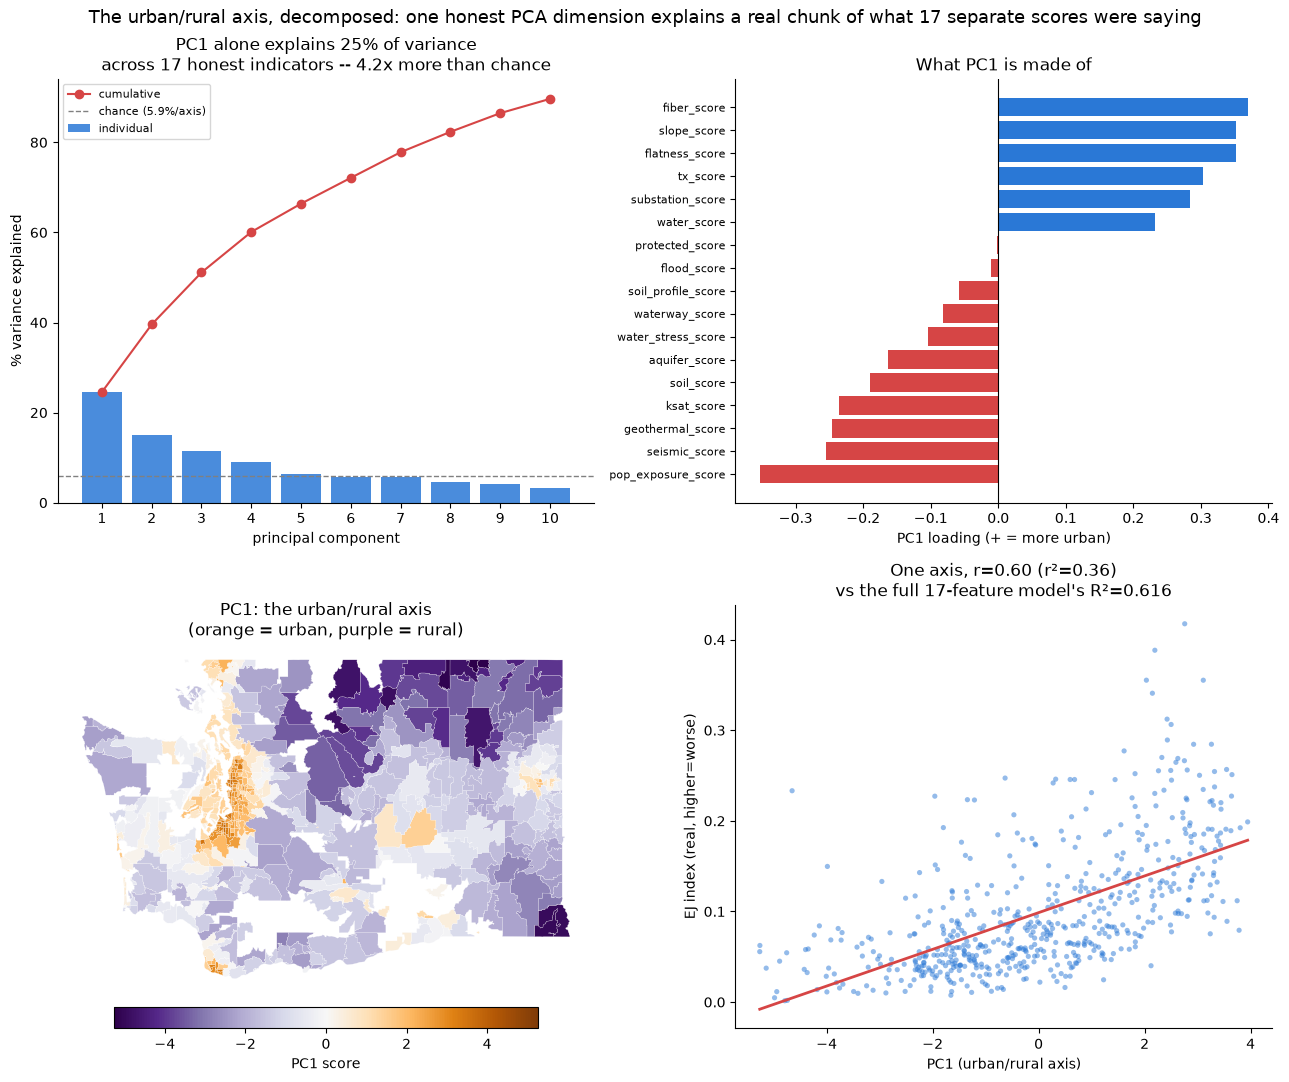

In [4]:
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

# 1. scree plot
ax = axes[0, 0]
n_show = 10
ax.bar(range(1, n_show + 1), evr[:n_show] * 100, color="#2a78d6", alpha=0.85, label="individual")
ax.plot(range(1, n_show + 1), np.cumsum(evr[:n_show]) * 100, "o-", color="#d64545", label="cumulative")
ax.axhline(chance * 100, color="gray", linestyle="--", linewidth=1, label=f"chance ({chance*100:.1f}%/axis)")
ax.set_xlabel("principal component")
ax.set_ylabel("% variance explained")
ax.set_title(f"PC1 alone explains {evr[0]*100:.0f}% of variance\nacross {len(PCA_COLS)} honest indicators -- {evr[0]/chance:.1f}x more than chance")
ax.legend(fontsize=8)
ax.set_xticks(range(1, n_show + 1))
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# 2. PC1 loadings
ax = axes[0, 1]
loadings_sorted = pd.Series(pca.components_[0], index=PCA_COLS).sort_values()
colors = ["#d64545" if v < 0 else "#2a78d6" for v in loadings_sorted.values]
ax.barh(range(len(loadings_sorted)), loadings_sorted.values, color=colors)
ax.set_yticks(range(len(loadings_sorted)))
ax.set_yticklabels(loadings_sorted.index, fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("PC1 loading (+ = more urban)")
ax.set_title("What PC1 is made of")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# 3. map of PC1
ax = axes[1, 0]
features_geojson = json.loads(zctas.to_json())["features"]


def zcta_rings(geometry):
    coords = geometry["coordinates"]
    polys = [coords] if geometry["type"] == "Polygon" else coords
    for poly in polys:
        yield np.array(poly[0])


all_lats = np.concatenate([r[:, 1] for f in features_geojson for r in zcta_rings(f["geometry"])])
lat_aspect = 1 / np.cos(np.radians(all_lats.mean()))
patches, values = [], []
for feat in features_geojson:
    for ring in zcta_rings(feat["geometry"]):
        patches.append(Polygon(ring, closed=True))
        values.append(feat["properties"]["pc1_urban_axis"])
coll = PatchCollection(patches, cmap="PuOr_r")
lim = max(abs(min(values)), abs(max(values)))
coll.set_array(np.array(values))
coll.set_clim(-lim, lim)
coll.set_edgecolor("white")
coll.set_linewidth(0.15)
ax.add_collection(coll)
ax.autoscale_view()
ax.set_aspect(lat_aspect)
ax.axis("off")
ax.set_title("PC1: the urban/rural axis\n(orange = urban, purple = rural)")
fig.colorbar(coll, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, label="PC1 score")

# 4. PC1 vs ej_index
ax = axes[1, 1]
ax.scatter(zctas["pc1_urban_axis"], zctas["ej_index"], s=14, alpha=0.5, color="#2a78d6", edgecolor="none")
z = np.polyfit(zctas["pc1_urban_axis"], zctas["ej_index"], 1)
xs = np.linspace(zctas["pc1_urban_axis"].min(), zctas["pc1_urban_axis"].max(), 50)
ax.plot(xs, np.polyval(z, xs), color="#d64545", linewidth=2)
ax.set_xlabel("PC1 (urban/rural axis)")
ax.set_ylabel("EJ index (real, higher=worse)")
ax.set_title(f"One axis, r={r_ej:.2f} (r\u00b2={r_ej**2:.2f})\nvs the full 17-feature model's R\u00b2=0.616")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.suptitle("The urban/rural axis, decomposed: one honest PCA dimension explains a real chunk of what 17 separate scores were saying", fontsize=13)
fig.tight_layout()
fig.savefig("dc_ej_urban_axis_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## PC2, and how far can two clean numbers get you?

PC1 is the urban/rural axis. What's PC2, and does adding it to a simple linear model get meaningfully closer to the full 17-feature random forest's R²=0.616 -- with two interpretable numbers instead of 17 correlated raw indicators?

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold

loadings2 = pd.Series(pca.components_[1], index=PCA_COLS).sort_values(key=abs, ascending=False)
print(f"PC2 explains {evr[1]*100:.1f}% of variance. Loadings, ranked by |loading|:")
print(loadings2.round(3))

pc2 = scores[:, 1]
r_pc2_ej = np.corrcoef(pc2, zctas["ej_index"])[0, 1]
print(f"\nPC2 alone vs ej_index: r={r_pc2_ej:.3f} -- weak on its own, a minor axis not a second dominant story.")
print("Loading pattern (high water_score/soil_profile_score + low seismic_score/geothermal_score moving together) "
      "reads like WA's real west/east geographic divide -- wetter and more seismically active west of the Cascades, "
      "drier and more geothermal east of them. A different split entirely from urban/rural, not a competing explanation of it.")

PC2 explains 15.0% of variance. Loadings, ranked by |loading|:
soil_profile_score    0.505
water_score           0.442
seismic_score        -0.431
geothermal_score     -0.272
waterway_score       -0.262
ksat_score            0.259
aquifer_score        -0.194
soil_score            0.184
fiber_score          -0.159
water_stress_score    0.139
flatness_score       -0.122
slope_score          -0.122
pop_exposure_score    0.054
substation_score     -0.053
tx_score             -0.046
protected_score      -0.021
flood_score          -0.010
dtype: float64

PC2 alone vs ej_index: r=-0.196 -- weak on its own, a minor axis not a second dominant story.
Loading pattern (high water_score/soil_profile_score + low seismic_score/geothermal_score moving together) reads like WA's real west/east geographic divide -- wetter and more seismically active west of the Cascades, drier and more geothermal east of them. A different split entirely from urban/rural, not a competing explanation of it.


In [6]:
y = zctas["ej_index"].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=0)
RF_FULL_R2 = 0.616  # dc_ej_predictors.ipynb, 17 raw honest features

X_pc1 = pc1.reshape(-1, 1)
X_pc12 = np.column_stack([pc1, pc2])

r2_pc1_cv = cross_val_score(LinearRegression(), X_pc1, y, cv=kf, scoring="r2").mean()
r2_pc12_cv = cross_val_score(LinearRegression(), X_pc12, y, cv=kf, scoring="r2").mean()

print(f"linear, PC1 alone:  CV R\u00b2 = {r2_pc1_cv:.3f}")
print(f"linear, PC1 + PC2:  CV R\u00b2 = {r2_pc12_cv:.3f}  (+{r2_pc12_cv - r2_pc1_cv:.3f} from adding PC2)")
print(f"\ncompare: full 17-feature random forest CV R\u00b2 = {RF_FULL_R2}")
print(f"two clean orthogonal numbers, plain linear regression, recover {r2_pc12_cv/RF_FULL_R2*100:.0f}% "
      f"of what a 17-feature black-box forest gets.")

linear, PC1 alone:  CV R² = 0.359
linear, PC1 + PC2:  CV R² = 0.395  (+0.035 from adding PC2)

compare: full 17-feature random forest CV R² = 0.616
two clean orthogonal numbers, plain linear regression, recover 64% of what a 17-feature black-box forest gets.


## Does the remaining gap need a 3rd PC, or a nonlinear model?

Real question, not assumed either way: does closing the gap between 2-PC linear and the full RF need more components, or curvature the two big axes don't have? Checked with three separate diagnostics rather than guessing which.

linear R² by number of PCs included (first 12):
  k= 1: R²=0.359
  k= 2: R²=0.395
  k= 3: R²=0.394
  k= 4: R²=0.415
  k= 5: R²=0.441
  k= 6: R²=0.459
  k= 7: R²=0.466
  k= 8: R²=0.466
  k= 9: R²=0.463
  k=10: R²=0.477
  k=11: R²=0.478
  k=12: R²=0.479
  ...
  k=17 (all honest components, = full linear model on all 17 raw indicators): R²=0.492

even with EVERY honest component in a straight line, linear tops out at 0.493 -- never reaches the RF's 0.616. That gap can only be nonlinearity/interactions, not missing components.

on PC1+PC2 only: linear R²=0.395, random forest R²=0.387 (no real difference)
-- no curvature to exploit in the two big axes themselves.

RF on all 17 honest PCs: R²=0.566 (compare: RF on the raw 17 honest features = 0.616 -- sanity check that PCA on the honest set is just a rotation, not a loss of information)

Conclusion: the missing chunk of R² needs BOTH more components AND nonlinear combination of them --
but that structure lives in the smaller, currently-unint

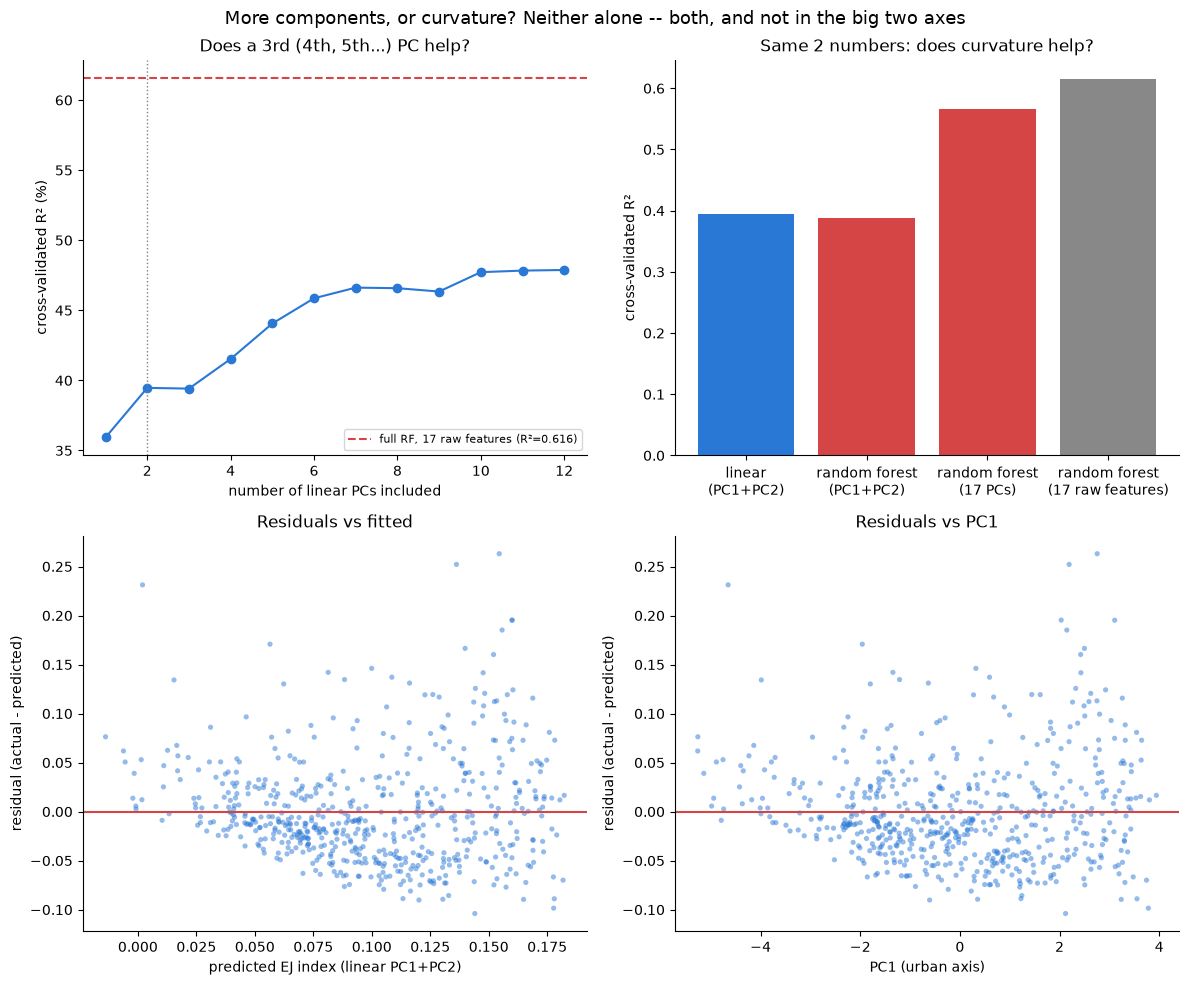

In [7]:
from sklearn.ensemble import RandomForestRegressor

# (a) R^2 vs number of linear PCs included
ks = range(1, len(PCA_COLS) + 1)
r2_by_k = np.array([cross_val_score(LinearRegression(), scores[:, :k], y, cv=kf, scoring="r2").mean() for k in ks])
print("linear R\u00b2 by number of PCs included (first 12):")
for k, r2 in list(zip(ks, r2_by_k))[:12]:
    print(f"  k={k:2d}: R\u00b2={r2:.3f}")
print(f"  ...\n  k={len(PCA_COLS)} (all honest components, = full linear model on all 17 raw indicators): R\u00b2={r2_by_k[-1]:.3f}")
print(f"\neven with EVERY honest component in a straight line, linear tops out at {r2_by_k.max():.3f} -- "
      f"never reaches the RF's {RF_FULL_R2}. That gap can only be nonlinearity/interactions, not missing components.")

# (b) linear vs nonlinear (RF) on the SAME 2 PCs -- isolates curvature specifically
rf2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
r2_rf_2 = cross_val_score(rf2, X_pc12, y, cv=kf, scoring="r2").mean()
print(f"\non PC1+PC2 only: linear R\u00b2={r2_pc12_cv:.3f}, random forest R\u00b2={r2_rf_2:.3f} "
      f"({'RF wins' if r2_rf_2 > r2_pc12_cv else 'no real difference'})")
print("-- no curvature to exploit in the two big axes themselves.")

rf_all = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
r2_rf_allpc = cross_val_score(rf_all, scores, y, cv=kf, scoring="r2").mean()
print(f"\nRF on all {len(PCA_COLS)} honest PCs: R\u00b2={r2_rf_allpc:.3f} (compare: RF on the raw 17 honest features = {RF_FULL_R2} -- "
      f"sanity check that PCA on the honest set is just a rotation, not a loss of information)")
assert r2_rf_allpc > r2_by_k.max(), "RF on all PCs doesn't beat the best linear model -- the nonlinearity claim doesn't hold, recheck"
print("\nConclusion: the missing chunk of R\u00b2 needs BOTH more components AND nonlinear combination of them --")
print("but that structure lives in the smaller, currently-uninterpreted PC3+ components, not in the two big axes.")

# (c) residual diagnostics from the linear PC1+PC2 model
pred_2 = cross_val_predict(LinearRegression(), X_pc12, y, cv=kf)
resid_2 = y - pred_2

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax = axes[0, 0]
ax.plot(list(ks)[:12], r2_by_k[:12] * 100, "o-", color="#2a78d6")
ax.axhline(RF_FULL_R2 * 100, color="#d64545", linestyle="--", label=f"full RF, 17 raw features (R\u00b2={RF_FULL_R2})")
ax.axvline(2, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("number of linear PCs included")
ax.set_ylabel("cross-validated R\u00b2 (%)")
ax.set_title("Does a 3rd (4th, 5th...) PC help?")
ax.legend(fontsize=8)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax = axes[0, 1]
ax.bar(["linear\n(PC1+PC2)", "random forest\n(PC1+PC2)", "random forest\n(17 PCs)", "random forest\n(17 raw features)"],
       [r2_pc12_cv, r2_rf_2, r2_rf_allpc, RF_FULL_R2],
       color=["#2a78d6", "#d64545", "#d64545", "#888888"])
ax.set_ylabel("cross-validated R\u00b2")
ax.set_title("Same 2 numbers: does curvature help?")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax = axes[1, 0]
ax.scatter(pred_2, resid_2, s=14, alpha=0.5, color="#2a78d6", edgecolor="none")
ax.axhline(0, color="#d64545", linewidth=1.5)
ax.set_xlabel("predicted EJ index (linear PC1+PC2)")
ax.set_ylabel("residual (actual - predicted)")
ax.set_title("Residuals vs fitted")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax = axes[1, 1]
ax.scatter(pc1, resid_2, s=14, alpha=0.5, color="#2a78d6", edgecolor="none")
ax.axhline(0, color="#d64545", linewidth=1.5)
ax.set_xlabel("PC1 (urban axis)")
ax.set_ylabel("residual (actual - predicted)")
ax.set_title("Residuals vs PC1")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.suptitle("More components, or curvature? Neither alone -- both, and not in the big two axes", fontsize=13)
fig.tight_layout()
fig.savefig("dc_ej_pc_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **Leakage-checked, not just PCA on everything.** The 4 columns that are literally the raw ingredients of `env_burden` (half of `ej_index`) are excluded from the PCA input entirely -- an earlier version of this notebook included them, and since they carried some of PC1's largest loadings, part of the original headline number was mechanical. Rebuilt clean; see the intro for the full story.
- **Why PCA, not just picking `fiber_score`:** the companion piece established qualitatively (correlation table + ablation) that several indicators ride one underlying axis. PCA makes that precise: a single number for how dominant the axis actually is, a full weighted composite instead of one indicator standing in for the rest, and a real visualization of it.
- **Not assumed to be "urban/rural" just because it's PC1.** Checked against the two known density proxies before calling it that -- both clear a 0.6 bar set before looking (asserted in-notebook).
- **What loads onto it, both directions.** Urban side: `fiber_score`, `slope_score`/`flatness_score` (cities sit on flatter land), `tx_score`/`substation_score` (grid infrastructure follows population), `pop_exposure_score` (inverted -- higher density pulls the axis the same direction). Rural side: `seismic_score`, `geothermal_score`, `ksat_score`.
- **PC2 is a different, minor axis**: `water_score`/`soil_profile_score`/`seismic_score`/`geothermal_score` moving together, reading like WA's real west/east geographic divide (wet + seismic west of the Cascades, dry + geothermal east). Weak alone -- a real but secondary story, not competing with PC1.
- **Diagnosed, not guessed, whether the remaining gap to the full RF needs more components or nonlinearity: both, but not where you'd expect.** Linear regression using literally all 17 honest components (mathematically equivalent to a full linear model on every raw honest indicator) never reaches the RF's R\u00b2=0.616 no matter how many components are added, so real nonlinear/interaction structure exists. But a random forest given only PC1+PC2 does no better than linear on the same two numbers -- the two big axes are themselves genuinely linear; there's no hidden curve in the story already told. The nonlinearity that closes the gap (RF on all 17 honest PCs recovers the raw-feature RF's number) lives in the smaller, currently-uninterpreted PC3+ components interacting with each other, not in urban/rural or the west/east split.
- n=591 WA ZCTAs, same EJ index construction as both companion pieces (`demog_index x env_burden`).